# 屋顶障碍物 U-Net：方法与结果

网站的「自动识别禁装区」用一个小型 U-Net 从 2014 年航拍中找出屋顶上的设备、楼梯间、检修口和排风口。这个 notebook 展示它是怎么做出来的：标签如何从 LiDAR 自动生成、模型和训练代码是什么样，以及训练好的模型成绩如何、在真实建筑上效果怎样。

训练本身在 GPU 服务器上用 `ml/train/train.py` 完成（见 `ml/train/README.md`），这里只展示代码、不重新训练；下面的结果全部来自那次训练的输出（`data/ml/result/unet`）和网站实际使用的模型（`public/models/roof-obstacles.onnx`）。

在本地运行需要 `ml/.venv`（见项目 README「重新生成数据和模型」）、已生成的数据集 `data/ml/dataset` 和下载回来的训练结果；最后一节还会联网读取纽约州航拍。

In [1]:
import csv
import inspect
import json
import sys
import time
import warnings
from pathlib import Path

# segmentation_models_pytorch pulls in tqdm, which warns without ipywidgets.
warnings.filterwarnings('ignore', message='IProgress not found')

import matplotlib.pyplot as plt
import numpy as np
import onnxruntime
from IPython.display import Code, display
from PIL import Image
from scipy import ndimage

ROOT = Path.cwd().parent if Path.cwd().name == 'ml' else Path.cwd()
sys.path[:0] = [str(ROOT / 'ml'), str(ROOT / 'ml' / 'train')]
import common          # noqa: E402  数据集、模型、损失和指标
import nyc_roofs       # noqa: E402  LiDAR 标签
import train           # noqa: E402  训练循环

DATASET = ROOT / 'data' / 'ml' / 'dataset'
RUN = ROOT / 'data' / 'ml' / 'result' / 'unet'
MODEL = ROOT / 'public' / 'models' / 'roof-obstacles.onnx'
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'Noto Sans CJK SC', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
RED = np.array([235, 40, 40])

def show_source(function):
    display(Code(inspect.getsource(function), language='python'))

## 1. 标签：从 LiDAR 自动生成

没有现成的"纽约屋顶设备"标注，所以用 2017 年纽约 LiDAR 当老师：在每栋楼的脚注内，取每 0.3 m 网格里最高的回波得到屋顶表面；对每栋楼单独做 8 m 窗口的形态学开运算，相当于把宽度小于 8 m 的凸起削平；两者相减，凸起 0.45 m 以上的就是障碍物。坡屋顶、屋顶边缘、不同高度屋面的交界和面积超过 45 m² 的整片凸起不参与训练。

In [2]:
show_source(nyc_roofs.obstacle_label)

def obstacle_label(points: np.ndarray, buildings: np.ndarray, bounds, size: int) -> tuple[np.ndarray, np.ndarray]:
    """Obstacle mask and valid (labeled) mask at image resolution.

    The roof surface is the highest return per cell inside building
    footprints; obstacles are what rises above its morphological opening.
    Pitched roofs, roof edges and steps between levels are not valid.
    """
    min_x, min_y, max_x, max_y = bounds
    cells = int(round((max_x - min_x) / DSM_CELL))
    inside = (points[:, 0] >= min_x) & (points[:, 0] < max_x) & (points[:, 1] >= min_y) & (points[:, 1] < max_y)
    p = points[inside]
    columns = ((p[:, 0] - min_x) / DSM_CELL).astype(int)
    rows = ((max_y - p[:, 1]) / DSM_CELL).astype(int)
    surface = np.full((cells, cells), -np.inf)
    np.maximum.at(surface, (rows, columns), p[:, 2])
    numbers = resize_nearest(buildings, cells)
    roof_cells = numbers > 0
    # Fill cells without a return from their neighbors.
    empty = ~np.isfinite(surface)
    if empty.all():
        zero = np.zeros((size, size), bool)
        return zero, zero
    nearest = ndimage.distance_transform_edt(empty, return_distances=False, return_indices=True)
    surface = surface[tuple(nearest)]
    # The roof each obstacle rises from, per building: outside its footprint
    # (the street, a lower or taller neighbor) counts as high, so the opening
    # only sees this building's own roof. Square windows are separable.
    window = 2 * int(OPENING_RADIUS / DSM_CELL) + 1
    pad = window
    opened = surface.copy()
    for number, box in enumerate(ndimage.find_objects(numbers), start=1):
        if box is None:
            continue
        rows_, columns_ = box
        padded = (slice(max(0, rows_.start - pad), rows_.stop + pad), slice(max(0, columns_.start - pad), columns_.stop + pad))
        own = numbers[padded] == number
        local = surface[padded]
        work = np.where(own, local, local[own].max() + 50)
        opened[padded][own] = ndimage.grey_opening(work, size=window)[own]
    inner = ndimage.binary_erosion(roof_cells, structure=disk(EDGE / DSM_CELL))
    # Flat buildings: most of the smoothed roof slopes gently.
    smooth = ndimage.median_filter(surface, size=5)
    gy, gx = np.gradient(smooth, DSM_CELL)
    flat = np.degrees(np.arctan(np.hypot(gx, gy))) < FLAT_DEGREES
    count = int(numbers.max())
    with np.errstate(invalid='ignore'):
        share = np.nan_to_num(ndimage.mean(flat, numbers, range(1, count + 1))) if count else np.array([])
    flat_buildings = np.concatenate([[False], np.asarray(share) >= FLAT_SHARE])
    # Steps between roof levels, seen in the opened (obstacle-free) surface.
    window = 2 * int(STEP_RADIUS / DSM_CELL) + 1
    step = (ndimage.grey_dilation(opened, size=window) - ndimage.grey_erosion(opened, size=window)) > STEP_RISE
    valid = inner & flat_buildings[numbers] & ~step
    rise = surface - opened
    raised = valid & (rise > MIN_RISE) & (rise < 15)
    raised = ndimage.binary_opening(raised, structure=np.ones((2, 2)))
    labels, count = ndimage.label(raised)
    if count:
        areas = np.asarray(ndimage.sum(raised, labels, range(1, count + 1))) * DSM_CELL * DSM_CELL
        too_big = np.isin(labels, np.nonzero(areas > MAX_OBJECT_AREA)[0] + 1)
        valid &= ~ndimage.binary_dilation(too_big, iterations=2)
        raised = np.isin(labels, np.nonzero((areas >= MIN_OBJECT_AREA) & (areas <= MAX_OBJECT_AREA))[0] + 1)
    return resize_nearest(raised, size) > 0, resize_nearest(valid, size) > 0

## 2. 数据集

全市随机抽 60 块 LiDAR（每块约 770 m 见方），切成 512 × 512 的切片（15 cm/像素，约 77 m 见方），每张配 2014、2016、2018 三个年份的航拍。训练、验证、测试集按 LiDAR 块划分，相邻区域不会跨集合。

切片数: {'train': 993, 'val': 86, 'test': 89}
LiDAR 块: 60 · 年份: ['2014', '2016', '2018'] · 像素: 0.15 m
障碍物占屋面像素: 5.2%


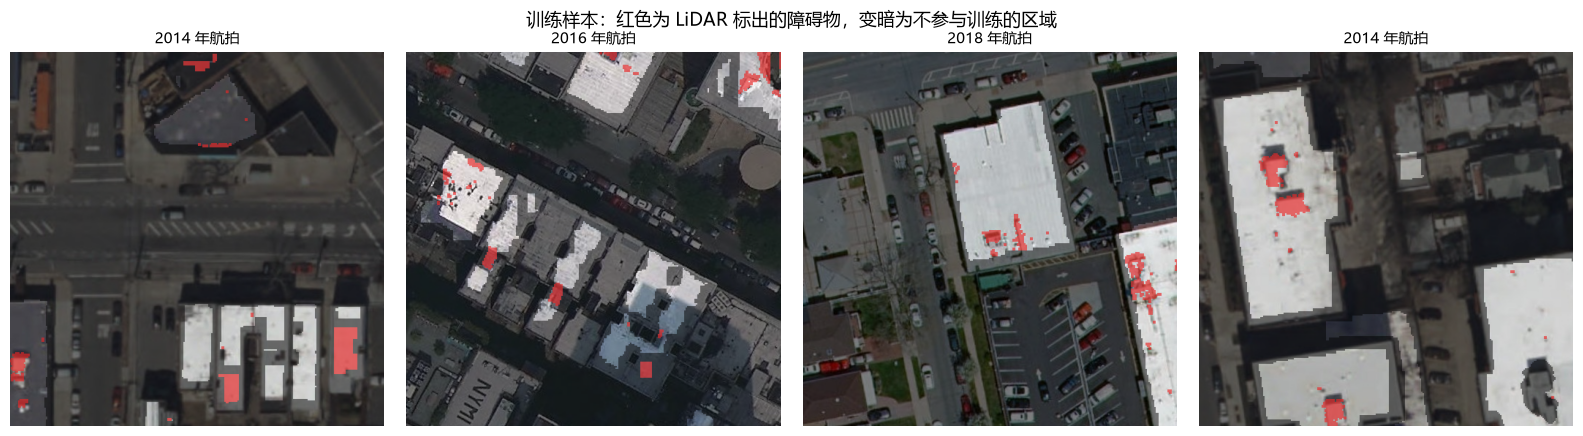

In [3]:
meta = json.loads((DATASET / 'meta.json').read_text())
splits = json.loads((DATASET / 'splits.json').read_text())
print('切片数:', {name: len(items) for name, items in splits.items()})
print('LiDAR 块:', len(meta['tiles']), '· 年份:', meta['years'], '· 像素:', meta['pixel_meters'], 'm')
print(f"障碍物占屋面像素: {meta['obstacle_share_of_roof']:.1%}")

def overlay(rgb, mask):
    image = rgb.astype(np.float32)
    image[mask == 0] *= 0.5
    image[mask == 2] = image[mask == 2] * 0.35 + RED * 0.65
    return image.clip(0, 255).astype(np.uint8)

rng = np.random.default_rng(5)
names = [n for n in rng.permutation(splits['train']) if (np.asarray(Image.open(DATASET / 'masks' / f'{n}.png')) == 2).mean() > 0.01][:4]
figure, axes = plt.subplots(1, 4, figsize=(16, 4.4))
for axis, name, year in zip(axes, names, ['2014', '2016', '2018', '2014']):
    rgb = np.asarray(Image.open(DATASET / 'images' / f'{name}_{year}.jpg').convert('RGB'))
    axis.imshow(overlay(rgb, np.asarray(Image.open(DATASET / 'masks' / f'{name}.png'))))
    axis.set_title(f'{year} 年航拍', fontsize=11)
    axis.axis('off')
figure.suptitle('训练样本：红色为 LiDAR 标出的障碍物，变暗为不参与训练的区域', fontsize=13)
plt.tight_layout()
plt.show()

## 3. 模型、损失和数据增强

U-Net + ImageNet 预训练的 MobileNetV2 编码器，解码器做了精简（导出后 fp16 只有 8 MB）。损失为 BCE（障碍物像素权重 3）+ Dice，只在有标签的像素上计算。训练时随机取一个年份的影像，再做裁剪、旋转、翻转和亮度、对比度、色调、gamma 扰动。

In [4]:
show_source(common.build_model)
show_source(common.masked_loss)
show_source(common.augment)

def build_model(encoder: str, pretrained: bool) -> torch.nn.Module:
    # A slim decoder keeps the exported model small for the browser.
    return smp.Unet(
        encoder_name=encoder,
        encoder_weights='imagenet' if pretrained else None,
        decoder_channels=(128, 64, 48, 32, 16),
        classes=1,
    )

def masked_loss(logits: torch.Tensor, target: torch.Tensor, valid: torch.Tensor, pos_weight: float) -> torch.Tensor:
    """BCE plus soft Dice, both over labeled pixels only."""
    weight = torch.tensor(pos_weight, device=logits.device)
    bce = F.binary_cross_entropy_with_logits(logits, target, pos_weight=weight, reduction='none')
    bce = (bce * valid).sum() / valid.sum().clamp(min=1)
    probability = torch.sigmoid(logits) * valid
    target = target * valid
    dice = 1 - (2 * (probability * target).sum() + 1) / (probability.sum() + target.sum() + 1)
    return bce + dice

def augment(image: np.ndarray, mask: np.ndarray, crop: int):
    size = image.shape[0]
    top, left = random.randint(0, size - crop), random.randint(0, size - crop)
    image, mask = image[top:top + crop, left:left + crop], mask[top:top + crop, left:left + crop]
    turns = random.randint(0, 3)
    image, mask = np.rot90(image, turns), np.rot90(mask, turns)
    if random.random() < 0.5:
        image, mask = image[:, ::-1], mask[:, ::-1]
    # Lighting and color differ between flights and seasons.
    gain = np.random.uniform(0.9, 1.1, 3).astype(np.float32)
    image = image * gain * np.float32(random.uniform(0.75, 1.25))
    mean = image.mean()
    image = (image - mean) * np.float32(random.uniform(0.8, 1.2)) + mean
    image = np.clip(image, 0, 1) ** np.float32(random.uniform(0.8, 1.25))
    return image.astype(np.float32), mask

## 4. 训练循环

AdamW（学习率 1e-3）+ 预热和余弦退火，混合精度；每轮结束在验证集上打分，验证 F1 最好的一轮保存为 `best.pt`。实际训练：RTX 4090D，batch 16，60 轮约 7 分钟。

In [5]:
show_source(train.train)

def train(
    data: Path,
    out: Path,
    *,
    encoder: str = 'mobilenet_v2',
    pretrained: bool = True,
    epochs: int = 60,
    batch: int = 16,
    crop: int = 384,
    lr: float = 1e-3,
    pos_weight: float = 3.0,
    workers: int = 8,
    max_steps: int = 0,
    resume: bool = False,
    seed: int = 0,
    on_epoch: Callable[[dict], None] | None = None,
) -> float:
    """Trains and returns the best validation F1; `on_epoch` gets each log row."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    data, out = Path(data), Path(out)
    out.mkdir(parents=True, exist_ok=True)
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    splits, years = load_splits(data), load_years(data)
    print(f'device {device} · train {len(splits["train"])} · val {len(splits["val"])} chips · years {years}', flush=True)

    train_loader = DataLoader(
        Chips(data, splits['train'], years, train=True, crop=crop),
        batch_size=batch, shuffle=True, num_workers=workers, pin_memory=device.type == 'cuda', drop_last=True,
        persistent_workers=workers > 0,
    )
    val_loader = DataLoader(Chips(data, splits['val'], years, train=False), batch_size=batch, num_workers=workers)

    model = build_model(encoder, pretrained=pretrained).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    steps_per_epoch = len(train_loader) if not max_steps else min(max_steps, len(train_loader))
    total = epochs * steps_per_epoch
    warmup = max(1, min(500, total // 10))
    schedule = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda step: (step + 1) / warmup if step < warmup else 0.5 * (1 + math.cos(math.pi * (step - warmup) / max(1, total - warmup))),
    )
    scaler = torch.amp.GradScaler(enabled=device.type == 'cuda')

    start, best = 0, -1.0
    if resume and (out / 'last.pt').exists():
        state = torch.load(out / 'last.pt', map_location=device)
        model.load_state_dict(state['model'])
        optimizer.load_state_dict(state['optimizer'])
        schedule.load_state_dict(state['schedule'])
        start, best = state['epoch'] + 1, state['best']
        print(f'resumed at epoch {start}', flush=True)

    config = {'encoder': encoder, 'crop': crop, 'pos_weight': pos_weight, 'epochs': epochs}
    (out / 'config.json').write_text(json.dumps(config, indent=1))
    log_path = out / 'log.csv'
    if not resume or not log_path.exists():
        with open(log_path, 'w', newline='') as handle:
            csv.writer(handle).writerow(LOG_FIELDS)

    for epoch in range(start, epochs):
        model.train()
        began, losses = time.time(), []
        for step, (image, target, valid) in enumerate(train_loader):
            if max_steps and step >= max_steps:
                break
            image, target, valid = image.to(device, non_blocking=True), target.to(device), valid.to(device)
            with torch.autocast(device_type=device.type, enabled=device.type == 'cuda'):
                logits = model(image)
            loss = masked_loss(logits.float(), target, valid, pos_weight)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            schedule.step()
            losses.append(loss.item())

        metrics = score(predict_all(model, val_loader, device), threshold=0.5)
        seconds = time.time() - began
        row = {'epoch': epoch, 'loss': float(np.mean(losses)), **metrics, 'seconds': seconds}
        with open(log_path, 'a', newline='') as handle:
            csv.writer(handle).writerow([round(row[field], 4) if isinstance(row[field], float) else row[field] for field in LOG_FIELDS])
        if on_epoch:
            on_epoch(row)
        else:
            print(f'epoch {epoch:3d} · loss {row["loss"]:.4f} · val f1 {metrics["f1"]:.3f} iou {metrics["iou"]:.3f} '
                  f'· objects found {metrics["object_recall"]

## 5. 训练过程

验证集成绩在第 40 轮左右基本稳定，最好的一轮是第 51 轮。之后不再上升，说明瓶颈在数据量而不是训练时长。

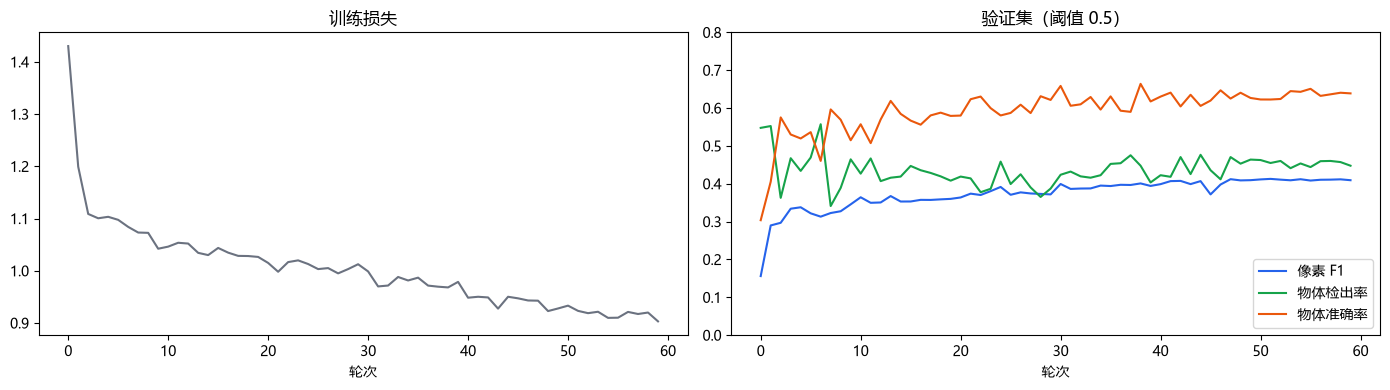

In [6]:
rows = list(csv.DictReader(open(RUN / 'log.csv')))
epochs = [int(r['epoch']) for r in rows]
figure, (left, right) = plt.subplots(1, 2, figsize=(14, 4))
left.plot(epochs, [float(r['loss']) for r in rows], color='#6b7280')
left.set_title('训练损失')
left.set_xlabel('轮次')
for key, label, color in [('f1', '像素 F1', '#2563eb'), ('object_recall', '物体检出率', '#16a34a'), ('object_precision', '物体准确率', '#ea580c')]:
    right.plot(epochs, [float(r[key]) for r in rows], label=label, color=color)
right.set_ylim(0, 0.8)
right.set_title('验证集（阈值 0.5）')
right.set_xlabel('轮次')
right.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 6. 阈值与测试成绩

在验证集上扫描 0.3–0.8 的阈值，取像素 F1 与物体 F1 之和最高的 0.4，再用它给测试集打分。

- **物体检出率**：LiDAR 标出的障碍物（≥ 0.3 m²）里，被模型碰到的比例。
- **物体准确率**：模型标出的区块里，确实有障碍物的比例。

这两个数字低估了实际效果：漏检的多是排屋屋顶上只有几个像素、航拍上看不见的小排风口；一部分"误报"其实是平贴的天窗，LiDAR 量不出高度差所以没标，但模型认出来了。

阈值 0.4 · 最好的一轮 51

          像素F1     IoU     检出率     准确率     障碍物
验证集       0.412   0.259    0.485    0.610     1671
测试集       0.434   0.277    0.486    0.595     1425


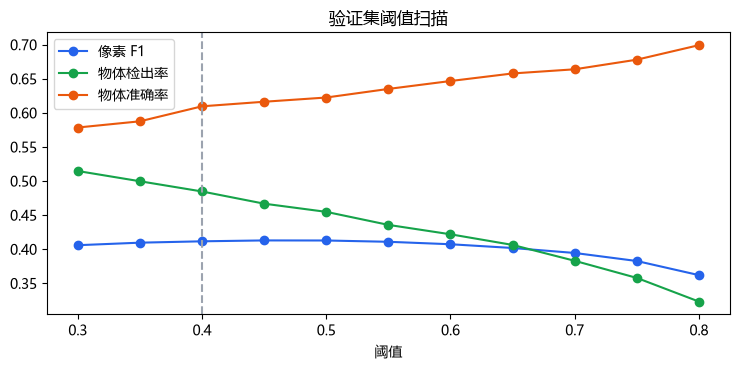

In [7]:
metrics = json.loads((RUN / 'metrics.json').read_text())
print(f"阈值 {metrics['threshold']} · 最好的一轮 {metrics['epoch']}\n")
print(f"{'':6}{'像素F1':>8}{'IoU':>8}{'检出率':>8}{'准确率':>8}{'障碍物':>8}")
for split, label in (('val', '验证集'), ('test', '测试集')):
    m = metrics[split]
    print(f"{label:6}{m['f1']:>9.3f}{m['iou']:>8.3f}{m['object_recall']:>9.3f}{m['object_precision']:>9.3f}{m['objects']:>9}")

thresholds = [float(t) for t in metrics['sweep']]
figure, axis = plt.subplots(figsize=(7.5, 3.8))
for key, label, color in [('f1', '像素 F1', '#2563eb'), ('object_recall', '物体检出率', '#16a34a'), ('object_precision', '物体准确率', '#ea580c')]:
    axis.plot(thresholds, [metrics['sweep'][t][key] for t in metrics['sweep']], marker='o', label=label, color=color)
axis.axvline(metrics['threshold'], color='#9ca3af', linestyle='--')
axis.set_xlabel('阈值')
axis.set_title('验证集阈值扫描')
axis.legend()
plt.tight_layout()
plt.show()

## 7. 测试集上的预测

测试集来自训练时没见过的街区。红色为 LiDAR 标出的障碍物，青色轮廓为模型预测，变暗为不参与评估的区域。

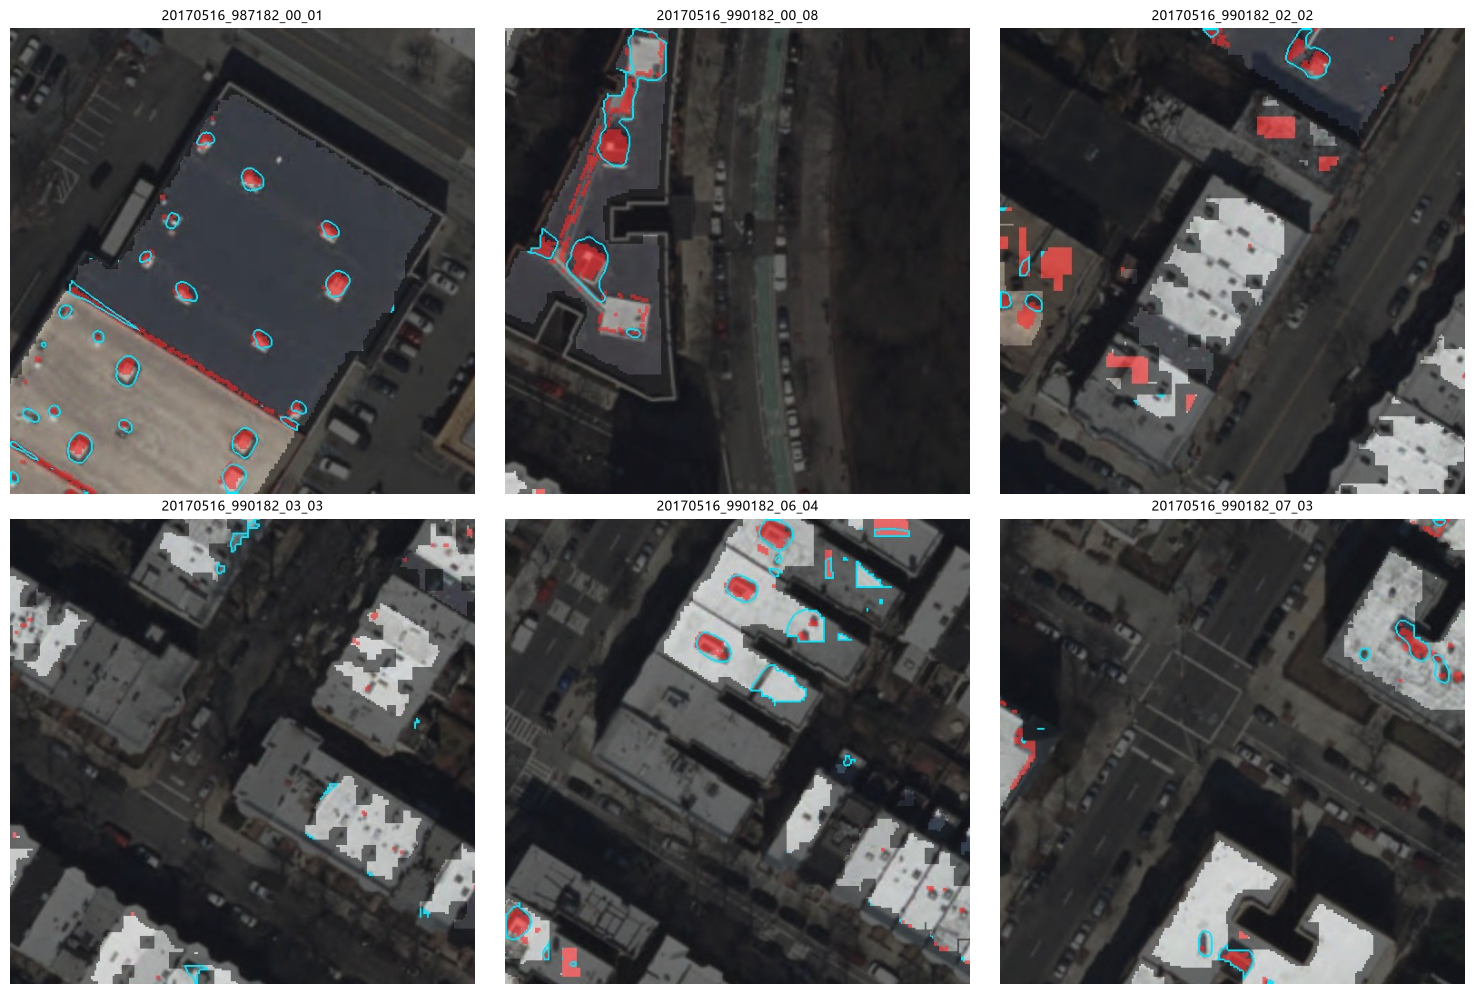

In [8]:
previews = sorted((RUN / 'previews').glob('*.jpg'))
figure, axes = plt.subplots(2, 3, figsize=(15, 10))
for axis, path in zip(axes.ravel(), [previews[i] for i in (2, 9, 15, 22, 30, 36)]):
    axis.imshow(Image.open(path))
    axis.set_title(path.stem, fontsize=9)
    axis.axis('off')
plt.tight_layout()
plt.show()

## 8. 网站用的模型在真实建筑上

用网站实际加载的 `public/models/roof-obstacles.onnx`（fp16，8 MB）在 CPU 上推理，输入与网站一致：2014 年航拍、15 cm/像素、ImageNet 归一化。三栋楼分别是导览用的 P.S. 321 小学（布鲁克林）、长岛市的一栋工业建筑和中城的高楼街区。网站里这一步在浏览器的 Web Worker 中用 ONNX Runtime Web 完成，之后再把预测区块框成矩形禁装区。

模型 roof-obstacles.onnx: 8.4 MB · 阈值 0.4


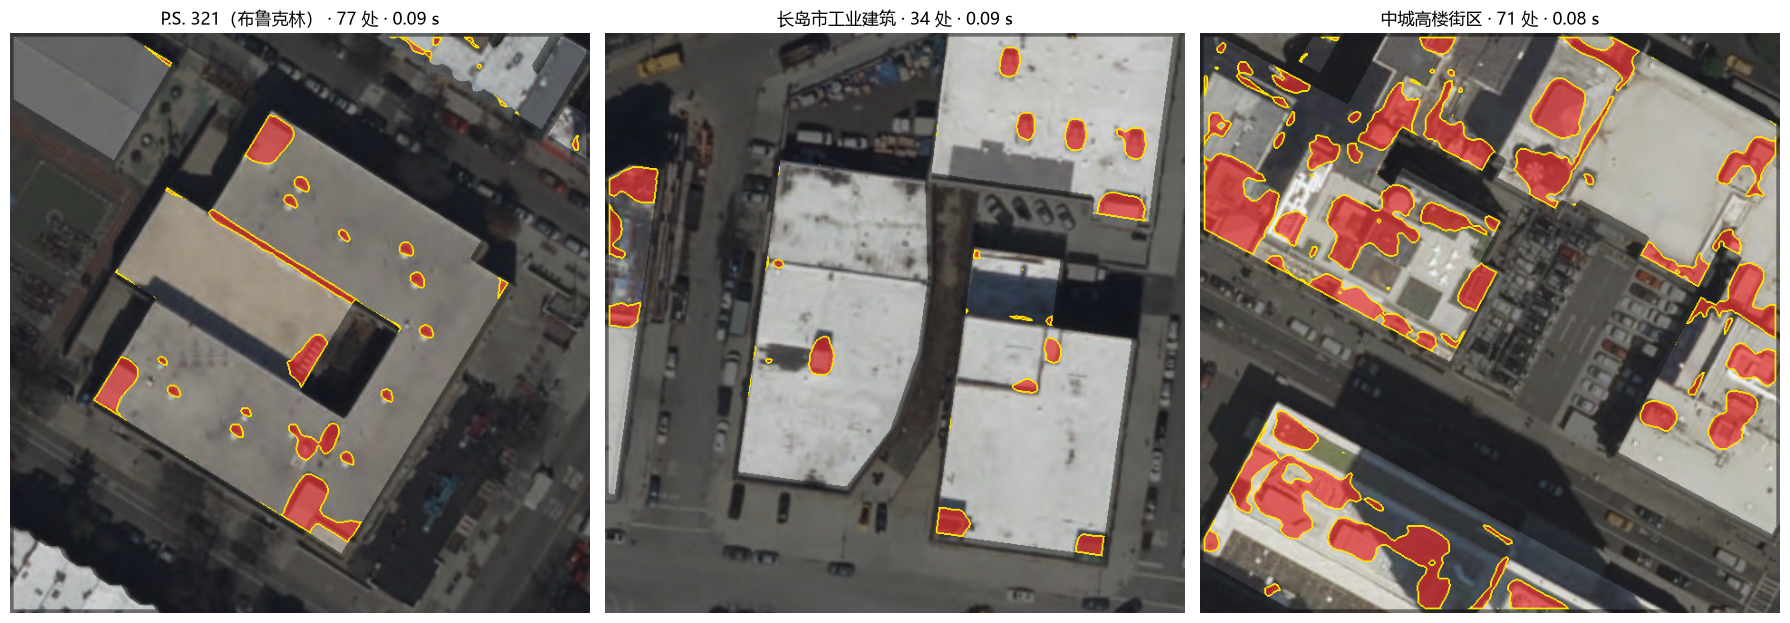

In [9]:
model_meta = json.loads((RUN / 'model.json').read_text())
session = onnxruntime.InferenceSession(str(MODEL), providers=['CPUExecutionProvider'])
mean = np.array(model_meta['input']['mean'], np.float32)
std = np.array(model_meta['input']['std'], np.float32)
threshold = model_meta['threshold']
print(f'模型 {MODEL.name}: {MODEL.stat().st_size / 1e6:.1f} MB · 阈值 {threshold}')

places = {'P.S. 321（布鲁克林）': (-73.978344, 40.671682), '长岛市工业建筑': (-73.9400, 40.7440), '中城高楼街区': (-73.9895, 40.7590)}
figure, axes = plt.subplots(1, 3, figsize=(18, 6.4))
for axis, (title, (lng, lat)) in zip(axes, places.items()):
    x, y = nyc_roofs.TO_UTM.transform(lng, lat)
    bounds = (x - 48, y - 48, x + 48, y + 48)
    rgb = nyc_roofs.ortho('2014', bounds, 640)
    buildings = nyc_roofs.rasterize(nyc_roofs.footprints(ROOT / 'data/processed/nyc-footprints.sqlite', bounds), bounds, nyc_roofs.PIXEL, (640, 640))
    roofs = ndimage.binary_erosion(buildings > 0, iterations=4)
    image = (rgb.astype(np.float32) / 255 - mean) / std
    started = time.time()
    probability = session.run(None, {'image': image.transpose(2, 0, 1)[None]})[0][0, 0]
    seconds = time.time() - started
    predicted = (probability >= threshold) & roofs
    shown = rgb.astype(np.float32)
    shown[~roofs] *= 0.55
    shown[predicted] = shown[predicted] * 0.35 + RED * 0.65
    edge = predicted & ~ndimage.binary_erosion(predicted, iterations=2)
    shown[edge] = [255, 230, 0]
    axis.imshow(shown.clip(0, 255).astype(np.uint8))
    axis.set_title(f'{title} · {ndimage.label(predicted)[1]} 处 · {seconds:.2f} s', fontsize=12)
    axis.axis('off')
plt.tight_layout()
plt.show()

## 小结

- LiDAR 自动生成的标签让我们不用人工标注就能训练，且部署时只需要航拍图。
- 测试集上约一半的 LiDAR 障碍物被找到，模型标出的区块约六成确有障碍物；独立的设备、楼梯间和水箱基本都能框住，并且不会像颜色算法那样把大片阴影当成障碍物。
- 局限：航拍是 2014 年的；高楼在航拍上有倾斜，预测会偏几米（中城那张可以看到）；屋面高差处的阴影线偶尔被误报。
- 提升方向：扩大数据集（现在只用了 60 块 LiDAR），或换更大的编码器。